# Headline card (P28) and Roman-season proxy (P29)

Regenerates every README figure from `data/`, which `compute.py` writes from existing per-star tables (T5 and pre-T5 dev_medium baselines, ranker v0 top-1 files from `runs/t27_ranker`). No pipeline runs.

In [1]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
HERE = Path('.').resolve()
D, F = HERE / 'data', HERE / 'figures'
F.mkdir(exist_ok=True)
BINS = ['<1d', '1-3d', '3-10d', '10-30d', '>30d']
SYS = ['hand (T5)', 'hand (pre-T5)', 'ranker v0']
COL = {'hand (T5)': '#525252', 'hand (pre-T5)': '#bdbdbd', 'ranker v0': '#2171b5'}
cards = json.load(open(D / 'cards.json'))
sens = pd.read_csv(D / 'population_sensitivity.csv'); per_bin = pd.read_csv(D / 'per_bin.csv')
cls = pd.read_csv(D / 'coverage_class.csv'); prec = pd.read_csv(D / 'precision_inputs.csv')
p29 = pd.read_csv(D / 'p29_consecutive35.csv'); shares = pd.read_csv(D / 'bin_shares.csv')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print((D / 'card_assigned.md').read_text()); print((D / 'card_fullyear.md').read_text())

**Headline card, dev_medium assigned, population `dev_medium`**

| Row | hand (T5) | hand (pre-T5) | ranker v0 |
|---|---|---|---|
| R0 success, raw (unweighted) | 0.147 ± 0.011 | 0.148 ± 0.010 | 0.188 ± 0.012 |
| R1 success, TESS coverage mix, P ≤ 30 d | 0.115 ± 0.023 | 0.116 ± 0.023 | 0.198 ± 0.028 |
| R2 success, population `dev_medium` | 0.080 ± 0.015 | 0.081 ± 0.015 | 0.137 ± 0.018 |
| R3 correct-only, population `dev_medium` | 0.046 ± 0.010 | 0.046 ± 0.010 | 0.072 ± 0.013 |
| R4 precision at rotator prevalence 0.1 | 0.206 ± 0.032 | 0.207 ± 0.032 | 0.251 ± 0.028 |
| R4 precision at rotator prevalence 0.3 | 0.401 ± 0.053 | 0.405 ± 0.053 | 0.421 ± 0.043 |
| R4 precision at rotator prevalence 0.5 | 0.494 ± 0.062 | 0.500 ± 0.063 | 0.487 ± 0.050 |
| R5 within 10%, most credible half | 0.218 ± 0.019 | 0.220 ± 0.018 | 0.372 ± 0.023 |
| R5 within 20%, most credible half | 0.268 ± 0.022 | 0.270 ± 0.019 | 0.494 ± 0.023 |
| n rotators / answered | 1000 / 211 | 1000 / 211 | 1000 / 282 |
| non

## Figure 1: the headline card

Each row's fixed definition is in `tools/headline_card.py` (`ROW_DEFINITIONS`). Error bars: bootstrap SE over stars (200 resamples). R4 SEs treat the non-rotator FP rate as fixed. Black ticks on R5: Claytor+2022's 46% / 69% (most credible half of their SMARTS-TESS test set).

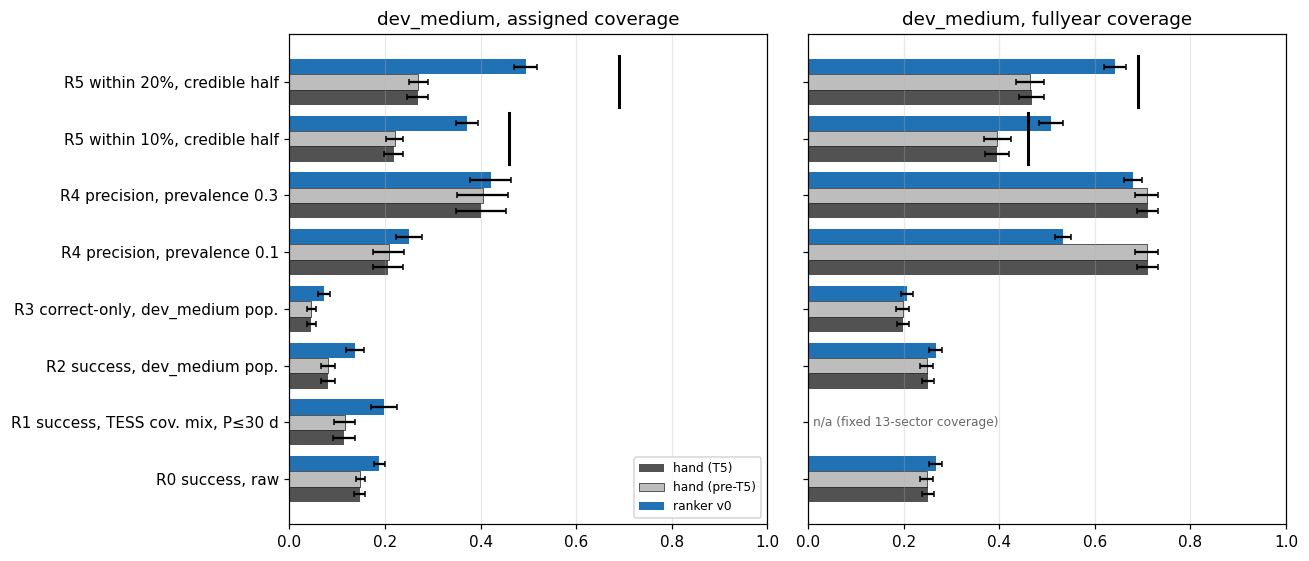

In [2]:
ROWS = [('R0 success, raw', 'R0_success_raw', None), ('R1 success, TESS cov. mix, P≤30 d', 'R1_success_tess_cov_P30', None),
        ('R2 success, dev_medium pop.', 'R2_success_pop', None), ('R3 correct-only, dev_medium pop.', 'R3_correct_pop', None),
        ('R4 precision, prevalence 0.1', 'R4_precision', '0.1'), ('R4 precision, prevalence 0.3', 'R4_precision', '0.3'),
        ('R5 within 10%, credible half', 'R5_within10_half', None), ('R5 within 20%, credible half', 'R5_within20_half', None)]
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, mode in zip(axes, ['assigned', 'fullyear']):
    y = np.arange(len(ROWS))
    for j, s in enumerate(SYS):
        c = cards[mode][s]; vals, errs = [], []
        for _, k, sub in ROWS:
            v, e = c['values'][k], c['se'][k]
            if sub is not None and v is not None: v, e = v[sub], e[sub]
            vals.append(np.nan if v is None else v); errs.append(0 if e is None else e)
        ax.barh(y + (j - 1) * 0.27, vals, 0.27, xerr=errs, color=COL[s], label=s, capsize=2,
                edgecolor='k' if s == 'hand (pre-T5)' else None, lw=0.4)
    for yy, ref in [(6, 0.46), (7, 0.69)]:
        ax.plot([ref, ref], [yy - 0.45, yy + 0.45], 'k-', lw=2)
    if mode == 'fullyear': ax.text(0.01, 1, 'n/a (fixed 13-sector coverage)', va='center', fontsize=8, color='0.4')
    ax.set_yticks(y, [r[0] for r in ROWS]); ax.invert_yaxis(); ax.set_xlim(0, 1); ax.grid(axis='x', alpha=.3)
    ax.set_title(f'dev_medium, {mode} coverage')
axes[0].legend(fontsize=8, loc='lower right')
fig.tight_layout(); fig.savefig(F / 'fig1_headline_card.png', bbox_inches='tight')

## Figure 2: what the period-population weighting does

(a) Per-bin success is the same under any period weighting; under assigned coverage it *is* changed by the coverage weighting (dashed = real TESS coverage mix). (b) Bin shares of dev_medium vs the candidate populations. (c) The headline success R2 under each population choice.

population              dev_medium  loguniform  mcq14_like   none  \
mode     system                                                     
assigned hand (T5)           0.080       0.096       0.051  0.080   
         hand (pre-T5)       0.081       0.097       0.051  0.081   
         ranker v0           0.137       0.150       0.102  0.138   
fullyear hand (T5)           0.251       0.242       0.314  0.251   
         hand (pre-T5)       0.248       0.237       0.314  0.248   
         ranker v0           0.267       0.266       0.313  0.267   

population              smarts_uniform  
mode     system                         
assigned hand (T5)               0.014  
         hand (pre-T5)           0.014  
         ranker v0               0.023  
fullyear hand (T5)               0.231  
         hand (pre-T5)           0.231  
         ranker v0               0.198  


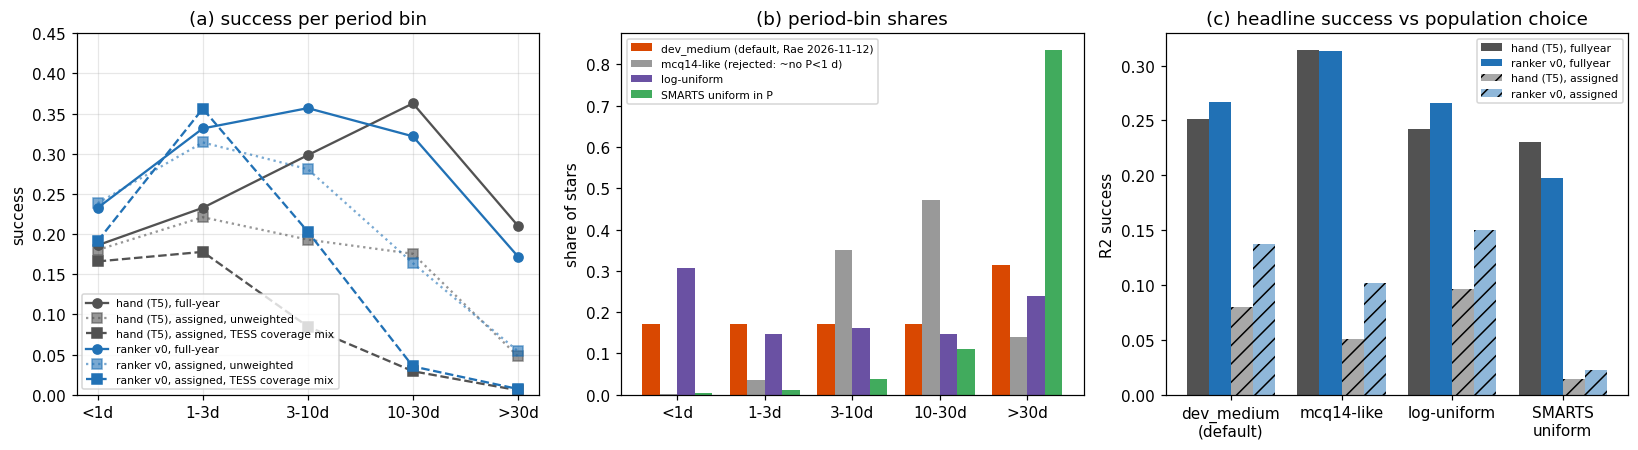

In [3]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(15, 4.2))
x = np.arange(len(BINS))
for s in ['hand (T5)', 'ranker v0']:
    fy = per_bin[(per_bin['mode'] == 'fullyear') & (per_bin.system == s)].set_index('bin').loc[BINS]
    asg = per_bin[(per_bin['mode'] == 'assigned') & (per_bin.system == s)].set_index('bin').loc[BINS]
    a1.plot(x, fy.success, 'o-', color=COL[s], label=f'{s}, full-year')
    a1.plot(x, asg.success, 's:', color=COL[s], alpha=0.6, label=f'{s}, assigned, unweighted')
    a1.plot(x, asg.success_covw, 's--', color=COL[s], label=f'{s}, assigned, TESS coverage mix')
a1.set_xticks(x, BINS); a1.set_ylabel('success'); a1.set_ylim(0, 0.45); a1.legend(fontsize=7); a1.grid(alpha=.3)
a1.set_title('(a) success per period bin')
w = 0.2
for j, (k, lab, c) in enumerate([('dev_medium', 'dev_medium (default, Rae 2026-11-12)', '#d94801'), ('mcq14_like', 'mcq14-like (rejected: ~no P<1 d)', '0.6'),
                                 ('loguniform', 'log-uniform', '#6a51a3'), ('smarts_uniform', 'SMARTS uniform in P', '#41ab5d')]):
    a2.bar(x + (j - 1.5) * w, shares[k], w, color=c, label=lab)
a2.set_xticks(x, BINS); a2.set_ylabel('share of stars'); a2.legend(fontsize=7); a2.set_title('(b) period-bin shares')
pops = ['dev_medium', 'mcq14_like', 'loguniform', 'smarts_uniform']
for j, (mode, s) in enumerate([('fullyear', 'hand (T5)'), ('fullyear', 'ranker v0'), ('assigned', 'hand (T5)'), ('assigned', 'ranker v0')]):
    g = sens[(sens['mode'] == mode) & (sens.system == s)].set_index('population').loc[pops]
    a3.bar(np.arange(4) + (j - 1.5) * w, g.success, w, color=COL[s], alpha=1 if mode == 'fullyear' else 0.5,
           hatch=None if mode == 'fullyear' else '//', label=f'{s}, {mode}')
a3.set_xticks(np.arange(4), ['dev_medium\n(default)', 'mcq14-like', 'log-uniform', 'SMARTS\nuniform']); a3.legend(fontsize=7)
a3.set_ylabel('R2 success'); a3.set_title('(c) headline success vs population choice')
fig.tight_layout(); fig.savefig(F / 'fig2_population_weighting.png', bbox_inches='tight')
print(sens.pivot_table(index=['mode', 'system'], columns='population', values='success').round(3))

## Figure 3: precision vs non-rotator prevalence

`prec(f) = f·S / (f·A + (1−f)·FP)` with S, A from the R2 weighting and FP from the T27 galaxy-stack negatives (coverage-weighted for assigned). Hand full-year answered 0 of 434 negatives; the shaded band runs from FP = 0 to the 95% upper limit.

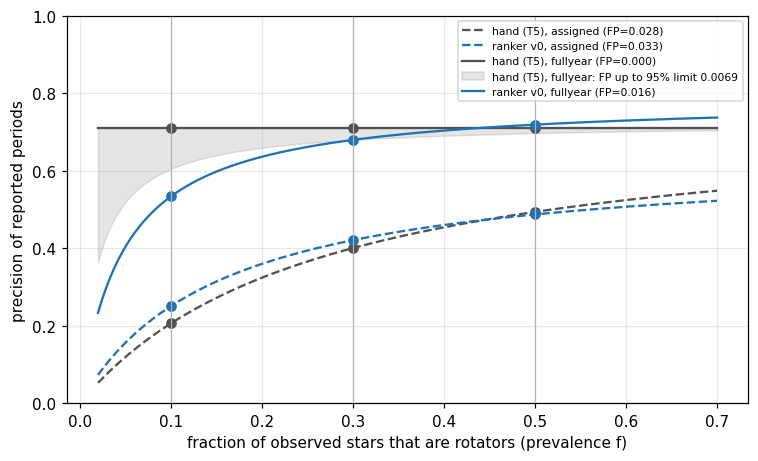

In [4]:
f = np.linspace(0.02, 0.7, 300)
fig, ax = plt.subplots(figsize=(7, 4.3))
pr = lambda S, A, FP, f: f * S / (f * A + (1 - f) * FP)
for _, r in prec[prec.system != 'hand (pre-T5)'].iterrows():
    ls = '-' if r['mode'] == 'fullyear' else '--'
    ax.plot(f, pr(r.S, r.A, r.FP, f), ls, color=COL[r.system], label=f'{r.system}, {r["mode"]} (FP={r.FP:.3f})')
    ax.plot([0.1, 0.3, 0.5], pr(r.S, r.A, r.FP, np.array([0.1, 0.3, 0.5])), 'o', color=COL[r.system])
    if np.isfinite(r.fp_upper95):
        ax.fill_between(f, pr(r.S, r.A, r.fp_upper95, f), pr(r.S, r.A, r.FP, f), color=COL[r.system], alpha=0.15,
                        label=f'{r.system}, {r["mode"]}: FP up to 95% limit {r.fp_upper95:.4f}')
for p in [0.1, 0.3, 0.5]: ax.axvline(p, color='0.7', lw=0.8)
ax.set_xlabel('fraction of observed stars that are rotators (prevalence f)'); ax.set_ylabel('precision of reported periods')
ax.set_ylim(0, 1); ax.legend(fontsize=7); ax.grid(alpha=.3)
fig.tight_layout(); fig.savefig(F / 'fig3_precision_vs_prevalence.png', bbox_inches='tight')

## Figure 4: success by coverage class (P ≤ 30 d), with the Roman-season proxy

dev_medium assigned, Wilson 95% intervals; percentages are each class's real TESS star-season share. Right: the `consecutive-3-5` class by period bin (~22 stars per bin, 39 at >30 d).

           system      bin    n  success     lo     hi  correct
0       hand (T5)      <1d   22    0.136  0.048  0.333    0.136
1       hand (T5)     1-3d   22    0.273  0.132  0.482    0.136
2       hand (T5)    3-10d   22    0.136  0.048  0.333    0.046
3       hand (T5)   10-30d   22    0.273  0.132  0.482    0.182
4       hand (T5)     >30d   39    0.051  0.014  0.169    0.051
5       hand (T5)  P<=30 d   88    0.204  0.134  0.300    0.125
6       hand (T5)      all  127    0.158  0.104  0.231    0.102
7   hand (pre-T5)      <1d   22    0.136  0.048  0.333    0.136
8   hand (pre-T5)     1-3d   22    0.273  0.132  0.482    0.136
9   hand (pre-T5)    3-10d   22    0.136  0.048  0.333    0.046
10  hand (pre-T5)   10-30d   22    0.273  0.132  0.482    0.182
11  hand (pre-T5)     >30d   39    0.051  0.014  0.169    0.051
12  hand (pre-T5)  P<=30 d   88    0.204  0.134  0.300    0.125
13  hand (pre-T5)      all  127    0.158  0.104  0.231    0.102
14      ranker v0      <1d   22    0.318

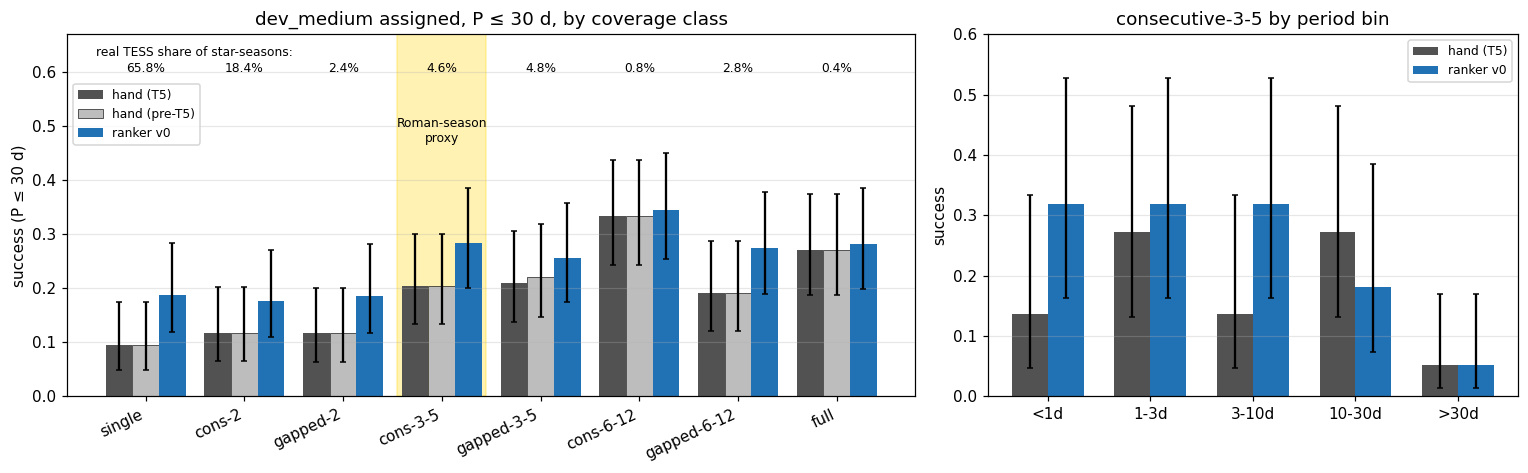

In [5]:
ORDER = ['single', 'consecutive-2', 'gapped-2', 'consecutive-3-5', 'gapped-3-5', 'consecutive-6-12', 'gapped-6-12', 'full']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.6, 1]))
x = np.arange(len(ORDER))
for j, s in enumerate(SYS):
    g = cls[(cls.system == s) & cls.P_le_30].set_index('coverage_class').loc[ORDER]
    a1.bar(x + (j - 1) * 0.27, g.success, 0.27, yerr=[g.success - g.success_lo, g.success_hi - g.success],
           color=COL[s], capsize=2, label=s, edgecolor='k' if s == 'hand (pre-T5)' else None, lw=0.4)
for xi, sh in zip(x, g.real_share): a1.text(xi, 0.6, f'{sh:.1%}', ha='center', fontsize=8)
a1.text(-0.5, 0.63, 'real TESS share of star-seasons:', fontsize=8)
a1.axvspan(2.55, 3.45, color='gold', alpha=0.3, zorder=0); a1.text(3, 0.47, 'Roman-season\nproxy', ha='center', fontsize=8)
a1.set_xticks(x, [o.replace('consecutive', 'cons') for o in ORDER], rotation=25, ha='right'); a1.set_ylim(0, 0.67)
a1.set_ylabel('success (P ≤ 30 d)'); a1.legend(fontsize=8, loc='upper left', bbox_to_anchor=(0, 0.88)); a1.grid(axis='y', alpha=.3)
a1.set_title('dev_medium assigned, P ≤ 30 d, by coverage class')
xb = np.arange(len(BINS))
for j, s in enumerate(['hand (T5)', 'ranker v0']):
    g = p29[p29.system == s].set_index('bin').loc[BINS]
    a2.bar(xb + (j - 0.5) * 0.35, g.success, 0.35, yerr=[g.success - g.lo, g.hi - g.success], color=COL[s], capsize=2, label=s)
a2.set_xticks(xb, BINS); a2.set_ylim(0, 0.6); a2.legend(fontsize=8); a2.grid(axis='y', alpha=.3)
a2.set_title('consecutive-3-5 by period bin'); a2.set_ylabel('success')
fig.tight_layout(); fig.savefig(F / 'fig4_coverage_class_roman_proxy.png', bbox_inches='tight')
print(p29.round(3).to_string()); print(json.load(open(D / 'p29_cost.json'))['minutes_1000_stars_4_workers'])